# French Motor Insurance Pricing

A reproducible actuarial walkthrough of the completed full-data study.

**业务问题：** 如何根据车辆和驾驶人特征估计年化预期赔款？

Methodology: [scikit-learn worked example](https://scikit-learn.org/stable/auto_examples/linear_model/plot_tweedie_regression_insurance_claims.html). Actual data source: a pinned historical snapshot from the CASdatasets authors; see the manifest. This is a methodological reproduction with train-only preprocessing.

In [1]:
from pathlib import Path
import json, subprocess, sys
import pandas as pd
from IPython.display import Image, display
ROOT = Path.cwd()
if not (ROOT / 'config.json').exists():
    ROOT = ROOT.parent
assert (ROOT / 'config.json').exists(), 'Open this notebook from the project or notebooks folder.'
sys.path.insert(0, str(ROOT))
REPORTS = ROOT / 'reports'
print('Project:', ROOT.name)

Project: non-life-insurance-pricing


## 1. Reproduce or inspect

Set `RECOMPUTE = True` to download verified source data if needed and rerun all models and sensitivities. The default displays the results already generated by the CLI. Raw data and model binaries are Git-ignored.

In [2]:
RECOMPUTE = False
if RECOMPUTE:
    subprocess.run([sys.executable, '-m', 'nonlife.run', '--download-only'], cwd=ROOT, check=True)
    subprocess.run([sys.executable, '-m', 'nonlife.run', '--sensitivity'], cwd=ROOT, check=True)
assert (REPORTS / 'run_metadata.json').exists(), 'Set RECOMPUTE=True, or run the CLI first.'
metadata = json.loads((REPORTS / 'run_metadata.json').read_text())
config = metadata['config']
pd.Series({'policies': metadata['cleaning_audit']['policy_count'], 'training': metadata['train_policies'], 'test': metadata['test_policies'], 'positive_loss_test': metadata['test_positive_loss_policies'], 'ID_overlap': metadata['split_overlap']})

policies              678013
training              508509
test                  169504
positive_loss_test      6237
ID_overlap                 0
dtype: int64

## 2. Actuarial targets and weights

Let $e_i$ denote exposure, $n_i$ adjusted claim count, and $S_i$ adjusted aggregate loss.

$$f_i=n_i/e_i,\qquad s_i=S_i/n_i,\qquad \pi_i=S_i/e_i.$$

Poisson models frequency with exposure weights; Gamma models positive severity with claim-count weights. The product $\hat f_i\hat s_i$ estimates annual pure premium. Tweedie models $\pi_i$ directly with exposure weights. Expected policy loss is $e_i\hat\pi_i$.

**注意：** 原基准对累计赔款、exposure 和 claim count 做了调整；这里的目标不是未经修改的原始损失。

In [3]:
pd.Series(metadata['cleaning_audit'], name='Cleaning audit')

count_capped_policies            9.000000e+00
exposure_capped_policies         1.224000e+03
amount_capped_policies           2.000000e+01
zero_amount_count_corrections    9.116000e+03
claim_amount_cap                 2.000000e+05
claim_amount_removed             7.737579e+06
modelled_total_claim_amount      5.217164e+07
modelled_exposure_years          3.583601e+05
positive_loss_policies           2.494400e+04
policy_count                     6.780130e+05
Name: Cleaning audit, dtype: float64

## 3. Holdout and preprocessing

The split is 75/25 with seed 0. Quantile bins, category levels and density scaling are fitted on training data only. Fixed benchmark regularization settings are used, with no test-set tuning. Separate policy IDs do not guarantee separate underlying insured entities.

Implementation: `nonlife/models.py`; complete equations and limitations: `docs/METHODOLOGY.md`.

In [4]:
pd.Series(config, name='Fixed configuration')

seed                               0
test_size                       0.25
claim_count_cap                    4
exposure_cap                     1.0
claim_amount_cap            200000.0
frequency_alpha               0.0001
severity_alpha                  10.0
tweedie_alpha                    0.1
tweedie_power                    1.9
evaluation_powers         [1.5, 1.9]
sensitivity_caps     [50000.0, None]
Name: Fixed configuration, dtype: object

## 4. Test-set performance

Compare deviance at an identical Tweedie power and target definition. Predicted / actual close to one indicates aggregate calibration. Gini describes ordering, not accurate monetary amounts.

In [5]:
metrics = pd.read_csv(REPORTS / 'metrics.csv')
metrics.loc[metrics['split'].eq('test'), ['model', 'predicted_actual', 'deviance_p1.5', 'deviance_p1.9', 'gini', 'weighted_mae']].round(4)

,model,predicted_actual,deviance_p1.5,deviance_p1.9,gini,weighted_mae
3,Baseline,1.0079,80.1324,34.3502,0.0000,276.9982
4,FrequencySeverity,1.0106,76.1705,33.8500,0.3055,272.2128
5,Tweedie,1.0197,76.4088,33.8783,0.2883,273.1249


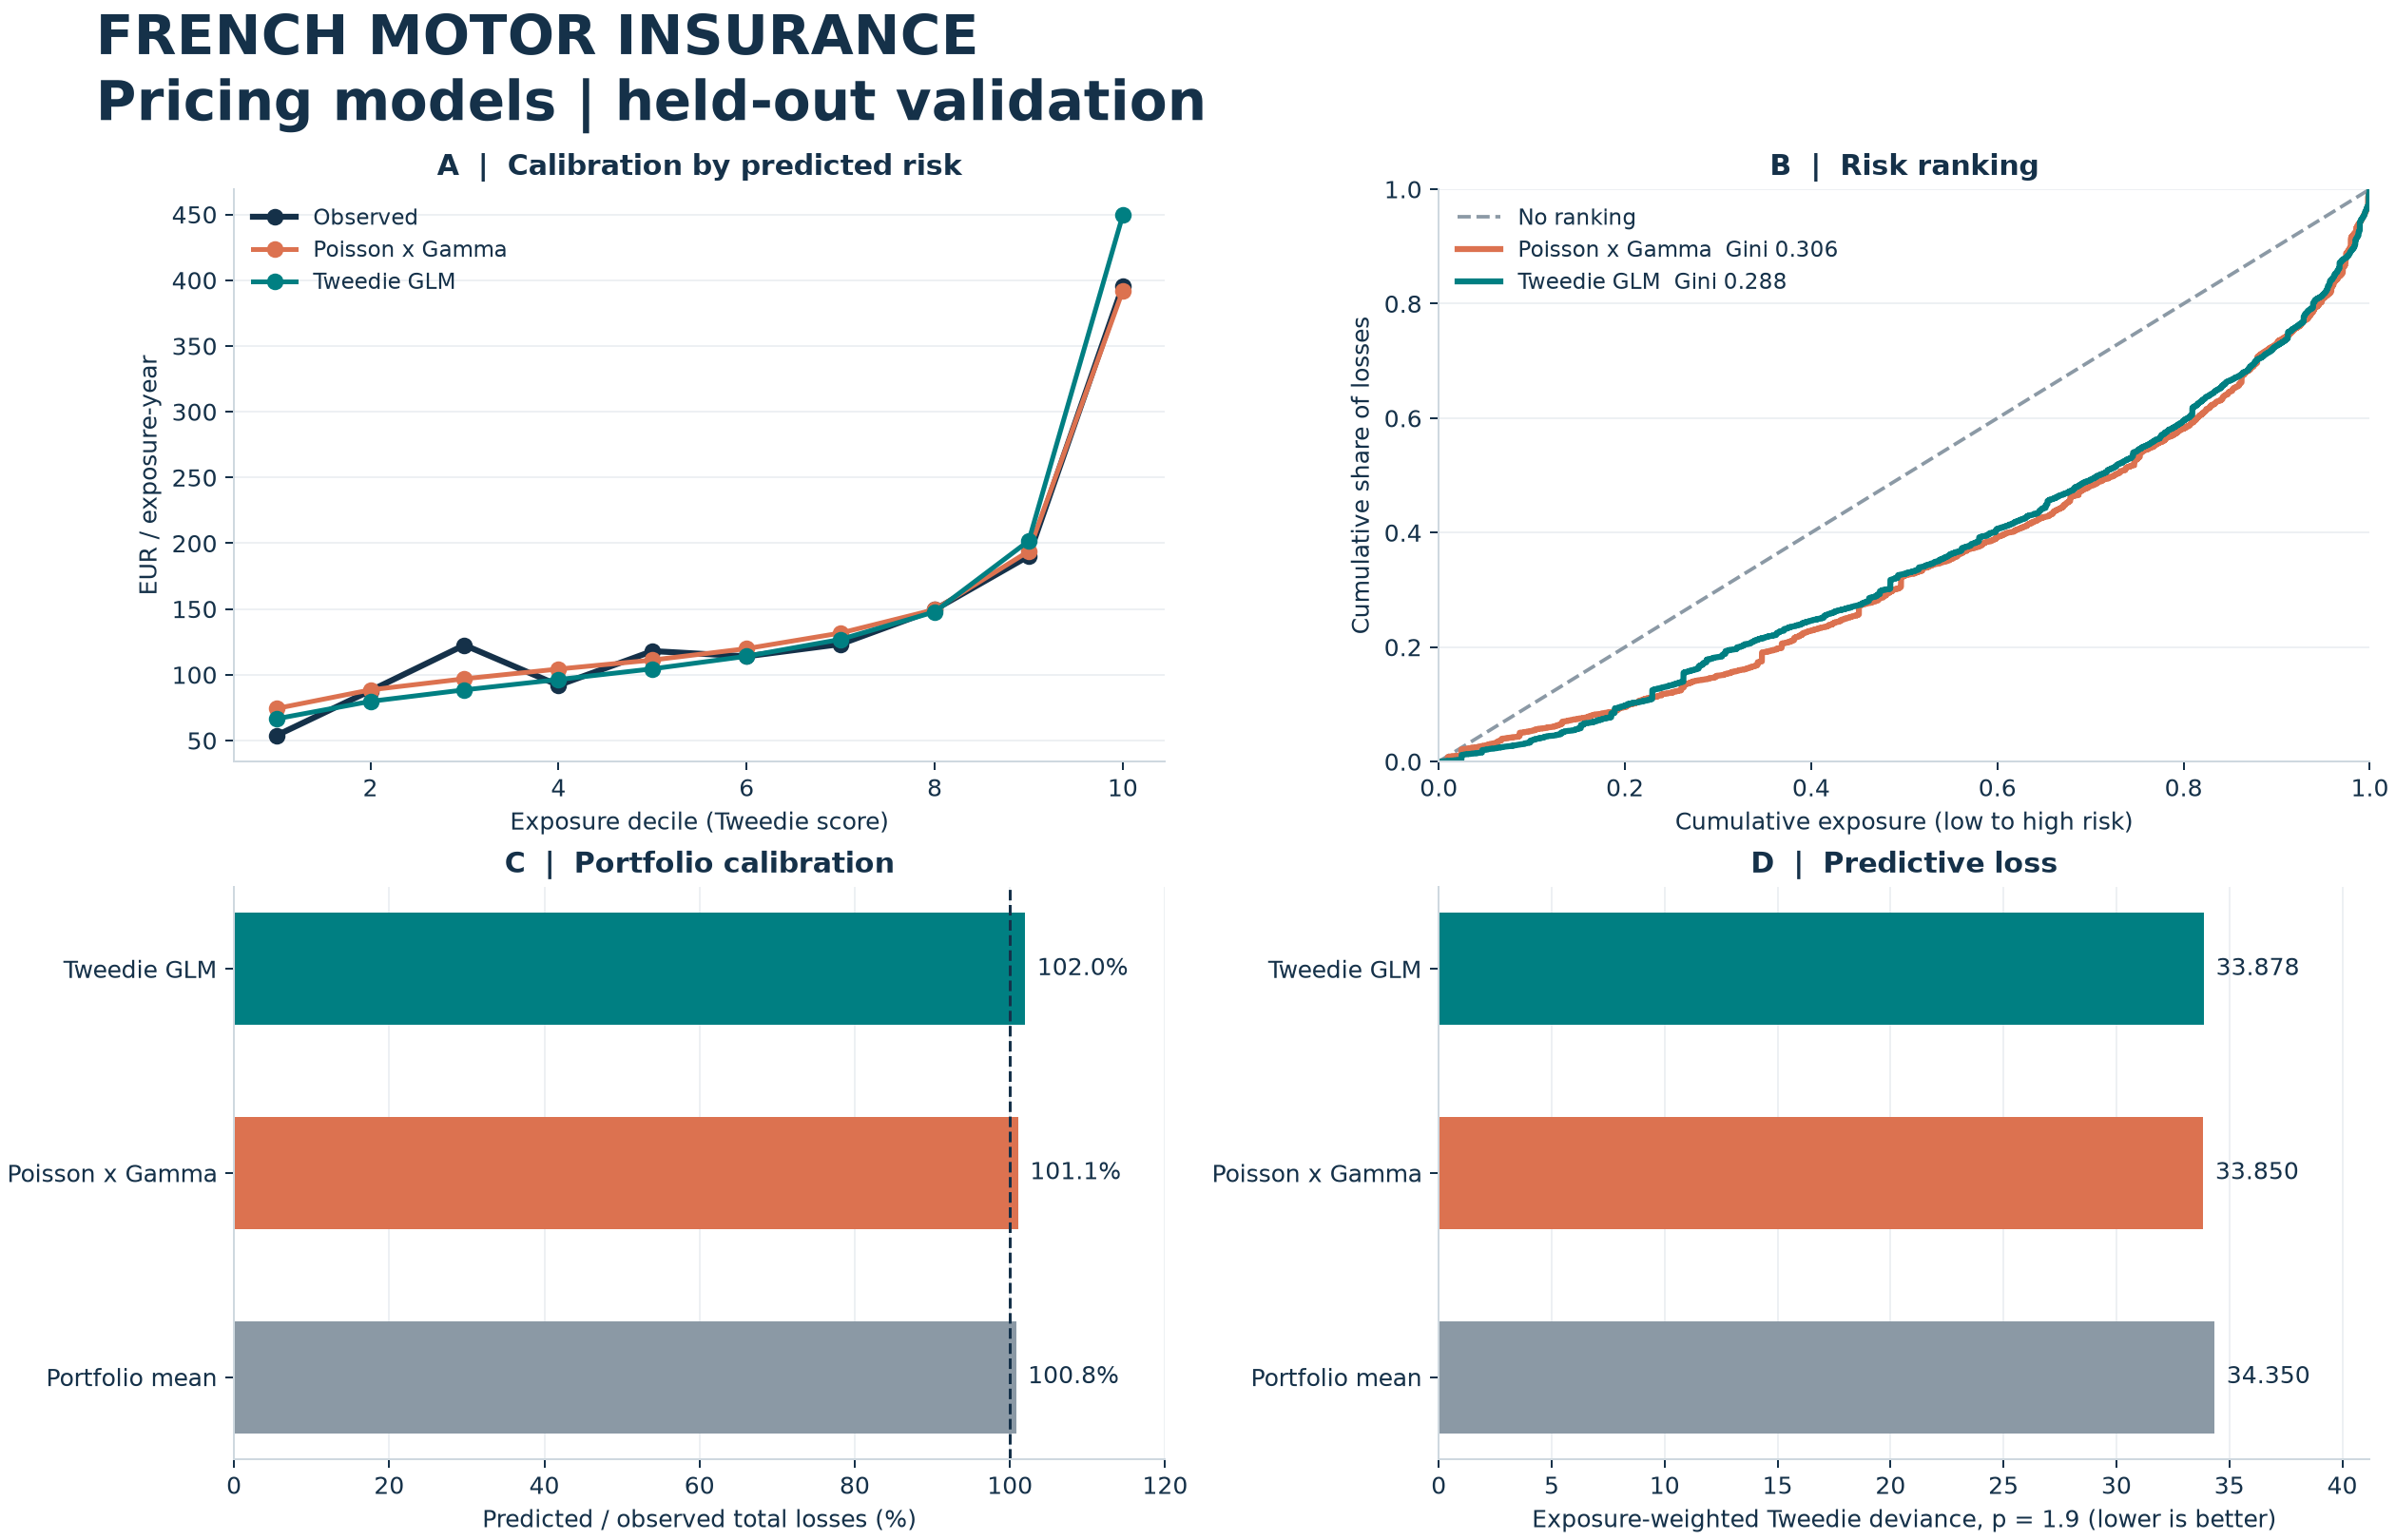

In [6]:
display(Image(filename=str(REPORTS / 'figures' / 'overview.png'), width=1000))

## 5. Segment calibration

A model can match total loss while missing specific segments. These charts use exposure-weighted rates in each age band. Treat small groups cautiously; these are descriptive diagnostics without credibility adjustment or significance tests.

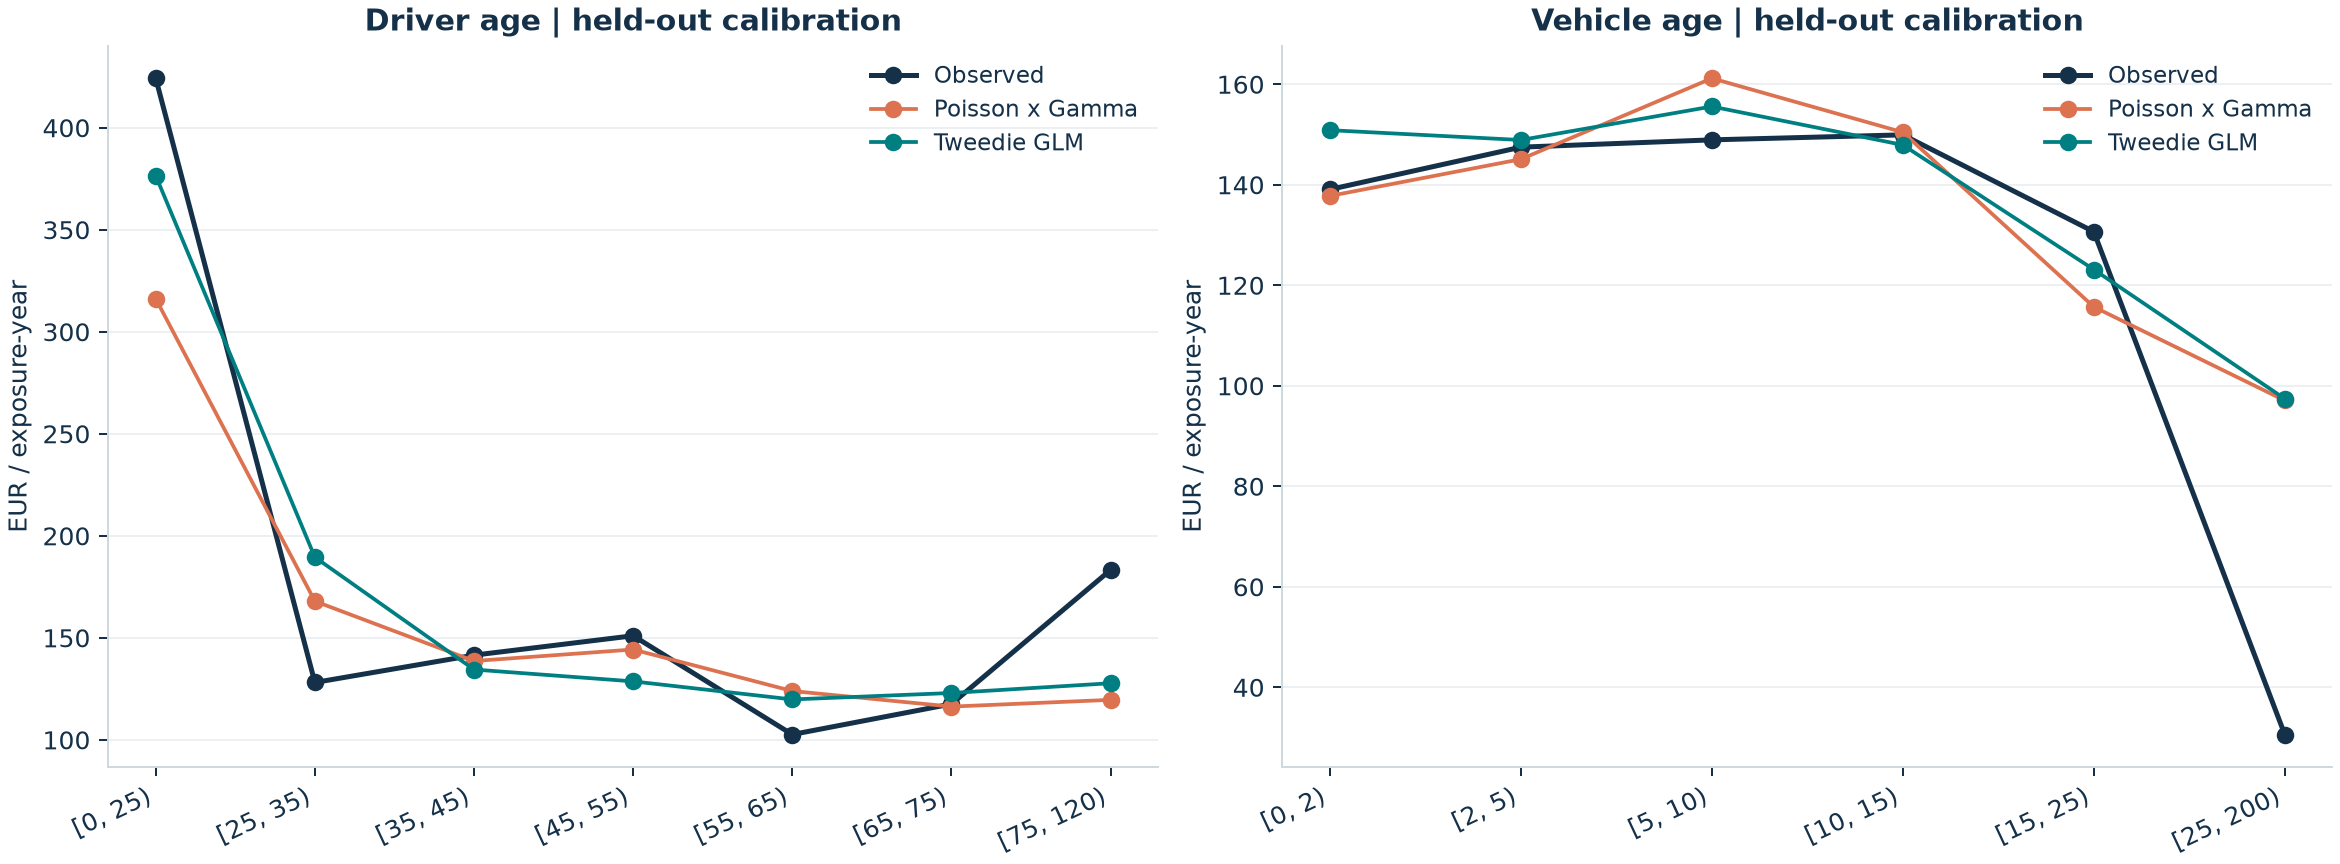

,group,exposure,actual_loss,policies,Baseline,FrequencySeverity,Tweedie,actual_rate,Baseline_rate,FrequencySeverity_rate,Tweedie_rate,tweedie_actual_expected
0,"[0, 25)",3095.77,1313263.38,7468,451581.97,978827.65,1165522.77,424.21,145.87,316.18,376.49,1.13
1,"[25, 35)",16119.41,2065226.35,35164,2351347.82,2707326.28,3054614.57,128.12,145.87,167.95,189.50,0.68
2,"[35, 45)",21833.65,3089773.43,42684,3184887.76,3027072.26,2935832.90,141.51,145.87,138.64,134.46,1.05
3,"[45, 55)",22505.27,3398782.17,41027,3282857.24,3247155.03,2895591.75,151.02,145.87,144.28,128.66,1.17
4,"[55, 65)",14155.09,1452681.03,24912,2064811.34,1754256.53,1695964.29,102.63,145.87,123.93,119.81,0.86
5,"[65, 75)",8199.05,963979.44,12764,1196000.11,953595.06,1008281.05,117.57,145.87,116.31,122.98,0.96
6,"[75, 120)",3883.83,711753.25,5485,566536.27,464530.07,496169.54,183.26,145.87,119.61,127.75,1.43


In [7]:
display(Image(filename=str(REPORTS / 'figures' / 'segment_calibration.png'), width=1000))
pd.read_csv(REPORTS / 'calibration_driver_age.csv').round(2)

## 6. Tail sensitivity

Each scenario refits on the same training IDs and evaluates against its own target. Compare models **within** a scenario. Different caps change the loss distribution, so absolute deviance across caps is not directly comparable.

In [8]:
sensitivity = pd.read_csv(REPORTS / 'sensitivity.csv')
sensitivity[['loss_cap', 'model', 'actual_loss', 'predicted_actual', 'deviance_p1.9', 'gini']].round(4)

,loss_cap,model,actual_loss,predicted_actual,deviance_p1.9,gini
0,200000.0,Baseline,12995459.05,1.0079,34.3502,0.0000
1,200000.0,FrequencySeverity,12995459.05,1.0106,33.8500,0.3055
2,200000.0,Tweedie,12995459.05,1.0197,33.8783,0.2883
3,50000.0,Baseline,11620777.51,0.9986,33.9444,0.0000
4,50000.0,FrequencySeverity,11620777.51,1.0012,33.4753,0.3015
5,50000.0,Tweedie,11620777.51,1.0056,33.4695,0.3063
6,Uncapped,Baseline,13123969.92,1.1919,34.4345,0.0000
7,Uncapped,FrequencySeverity,13123969.92,1.2030,33.9367,0.2975
8,Uncapped,Tweedie,13123969.92,1.1820,33.9977,0.2694


## 7. What this demonstrates

- Correct exposure and claim-count weighting, with a traceable data audit.
- Separation of ranking performance and monetary calibration.
- Explicit loss-cap assumptions and same-split sensitivity.
- A reproducible codebase and offline interactive report.

**Limitations:** single random holdout, potentially repeated risks, sparse large losses, no forward-year validation, no expenses or inflation loading.

Open `reports/dashboard.html` in a browser to interact with the figures. Next work could study group-aware validation and uncertainty before adding more complex models.